# Trios: DA forecast → ID forecast → delivery

A trio $n$ is one path of RES availability $(r^{DA}_n, r^{ID}_n, r^{RD}_n)$. Four ways to draw them around the input forecast $r$:

| | 1.1 chained | 1.2 chained, DA fixed | 2. centred | 3. forecast refinement |
|---|---|---|---|---|
| DA | $r + e^{DA}_n$ | $r$ | $r + e^{DA}_n$ | $r$ |
| ID | $r^{DA}_n + e^{ID}_n$ | $r + e^{ID}_n$ | $r + e^{ID}_n$ | $r + \delta_n$ |
| RD | $r^{ID}_n + e^{RD}_n$ | $r^{ID}_n + e^{RD}_n$ | $r + e^{RD}_n$ | $r^{ID}_n + \omega_n$ |

Draw around a centre: $x \sim \mathcal D(\bar r, \sigma)$ ⟺ $x_w = \Pi(\bar r_w + e_w)$, $e_w \sim \mathcal U[-\sigma\bar r_w, \sigma\bar r_w]$ (uniform) or $\mathcal N(0, (\sigma\bar r_w)^2)$ (normal),
independently per unit and per trio; $\Pi$ clips to $[0, R^{\max}]$.

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from power_system_data import PowerSystemData

## Inputs

In [98]:
case = '../data/intraday_case'
data = PowerSystemData.from_csv(case)

r = data.expected_DA_res_vec                 # input RES forecast
r_max = data.res_max_vec                     # installed capacity (clipping)
units = data.RENEWABLES

sigma_da, sigma_id, sigma_rd = 0.10, 0.04, 0.02    # sigma_DA >= sigma_ID >= sigma_RD
N, seed = 3, 42

pd.DataFrame({"forecast r": r, "capacity": r_max}, index=units)

,forecast r,capacity
R1,180.0,250.0
R2,70.0,120.0


## Draw helpers

In [99]:
def clip(x, r_max=None):
    """Pi: availability within [0, r_max]."""
    return np.clip(x, 0, np.inf if r_max is None else r_max)


def draw_around(rng, centre, sigma, N, dist="uniform"):
    """Deviation e (N x R) around `centre` (R or N x R), spread sigma * centre:
    uniform on [-sigma c, sigma c], or normal with std sigma c."""
    s = np.broadcast_to(sigma * np.asarray(centre, float), (N, np.shape(centre)[-1]))
    return rng.uniform(-s, s) if dist == "uniform" else rng.normal(0, s)


Z95 = 1.96                                                             # normal: show the 95 % range


def draw_range(centre, sigma, N, dist="uniform", r_max=None):
    """Range a value drawn by draw_around(centre, sigma) can fall in (N x R, lo and hi), clipped like the value:
    uniform: centre +- sigma c (all possibilities), normal: centre +- 1.96 sigma c (95 % of them)."""
    c = np.broadcast_to(np.asarray(centre, float), (N, np.shape(centre)[-1]))
    half = sigma * c * (1.0 if dist == "uniform" else Z95)
    return clip(c - half, r_max), clip(c + half, r_max)


def as_trios(r_da, r_id, r_rd, units, ranges=None, **meta):
    """ranges: {stage: (lo, hi)} range each value was drawn in (a fixed stage has none)."""
    frame = lambda x: pd.DataFrame(np.array(x, float), columns=units).rename_axis("trio")
    N = len(r_id)
    rng_ = {s: (frame(lo), frame(hi)) for s, (lo, hi) in (ranges or {}).items()}
    return dict(DA=frame(np.broadcast_to(r_da, np.shape(r_id))), ID=frame(r_id), RD=frame(r_rd), N=N,
                range=rng_, **meta)

## Method 1: chained trios

Each stage moves away from the stage before it, by a range set for that stage ($\sigma_{DA} \ge \sigma_{ID} \ge \sigma_{RD}$).

- **Option 1 (1.1):** $r^{DA}_n \sim \mathcal D(r, \sigma_{DA})$, $r^{ID}_n \sim \mathcal D(r^{DA}_n, \sigma_{ID})$, $r^{RD}_n \sim \mathcal D(r^{ID}_n, \sigma_{RD})$. The DA forecast varies between trios.
- **Option 2 (1.2):** $r^{DA}_n = r$, then the same chain. The DA forecast is fixed between trios.

The steps add up, and they are proportional to the previous value.

In [100]:
def trios_chained(r, sigma_da, sigma_id, sigma_rd, N, seed=None, r_max=None, units=None,
                  dist="uniform", fix_da=False):
    """Method 1. fix_da=False: option 1 (DA drawn around r); fix_da=True: option 2 (DA = r, sigma_da unused)."""
    assert sigma_id >= sigma_rd and (fix_da or sigma_da >= sigma_id), "expected sigma_DA >= sigma_ID >= sigma_RD"
    rng = np.random.default_rng(seed)
    r = np.asarray(r, float)
    r_da = np.broadcast_to(r, (N, len(r))) if fix_da else clip(r + draw_around(rng, r, sigma_da, N, dist), r_max)
    r_id = clip(r_da + draw_around(rng, r_da, sigma_id, N, dist), r_max)
    r_rd = clip(r_id + draw_around(rng, r_id, sigma_rd, N, dist), r_max)
    name = "1.2 chained, DA fixed" if fix_da else "1.1 chained"
    ranges = {"ID": draw_range(r_da, sigma_id, N, dist, r_max),        # around THIS trio's DA
              "RD": draw_range(r_id, sigma_rd, N, dist, r_max)}        # around THIS trio's ID
    if not fix_da:
        ranges["DA"] = draw_range(r, sigma_da, N, dist, r_max)
    return as_trios(r_da, r_id, r_rd, units, ranges=ranges, method=name, dist=dist,
                    sigma=dict(DA=0.0 if fix_da else sigma_da, ID=sigma_id, RD=sigma_rd))

## Method 2: centred trios

Each stage is an independent deviation from the same reference forecast:
$r^{t}_n \sim \mathcal D(r, \sigma_t)$, $t \in \{DA, ID, RD\}$, independently. The stages of a trio are uncorrelated.

In [101]:
def trios_centred(r, sigma_da, sigma_id, sigma_rd, N, seed=None, r_max=None, units=None, dist="uniform"):
    """Method 2: every stage drawn independently around r."""
    assert sigma_da >= sigma_id >= sigma_rd, "expected sigma_DA >= sigma_ID >= sigma_RD"
    rng = np.random.default_rng(seed)
    r = np.asarray(r, float)
    r_da, r_id, r_rd = (clip(r + draw_around(rng, r, s, N, dist), r_max) for s in (sigma_da, sigma_id, sigma_rd))
    ranges = {s: draw_range(r, sg, N, dist, r_max) for s, sg in zip(STAGES, (sigma_da, sigma_id, sigma_rd))}
    return as_trios(r_da, r_id, r_rd, units, ranges=ranges, method="2. centred", dist=dist,
                    sigma=dict(DA=sigma_da, ID=sigma_id, RD=sigma_rd))

## Method 3: forecast refinement

One DA forecast, refined at the ID, then revealed at delivery:
$r^{DA}_n = r$, $r^{ID}_n = \Pi(r + \delta_n)$, $r^{RD}_n = \Pi(r^{ID}_n + \omega_n)$, with
$\operatorname{std}(\delta_n) = \sqrt{\sigma_{DA}^2 - \sigma_{ID}^2}\, r$ (learnt by the ID) and $\operatorname{std}(\omega_n) = \sigma_{ID}\, r$ (still unknown at the ID),
independent, normal or uniform with the same std. Total error after DA: $\sigma_{DA} r$, whatever $\sigma_{ID}$.

In [102]:
def trios_forecast(r, sigma_da, sigma_id, N, seed=None, r_max=None, units=None, dist="normal"):
    """Method 3: DA = r, ID = DA + delta, RD = ID + omega; uniform has the same std as normal (half-width sqrt(3) std)."""
    assert sigma_id <= sigma_da, "the error left at ID cannot be larger than at DA"
    rng = np.random.default_rng(seed)
    r = np.asarray(r, float)
    k = np.sqrt(3) if dist == "uniform" else 1.0                       # draw_around uses the half-width for uniform
    r_da = np.broadcast_to(r, (N, len(r)))
    s_id, s_rd = k * np.sqrt(sigma_da ** 2 - sigma_id ** 2), k * sigma_id   # spreads as fractions of r
    r_id = clip(r_da + draw_around(rng, r, s_id, N, dist), r_max)
    r_rd = clip(r_id + draw_around(rng, r, s_rd, N, dist), r_max)
    half_rd = draw_range(r, s_rd, N, dist)[1] - r                      # half-width of the RD draw [MW]
    ranges = {"ID": draw_range(r, s_id, N, dist, r_max),               # around r
              "RD": (clip(r_id - half_rd, r_max), clip(r_id + half_rd, r_max))}   # around THIS trio's ID
    return as_trios(r_da, r_id, r_rd, units, ranges=ranges, method="3. forecast refinement", dist=dist,
                    sigma=dict(DA=sigma_da, ID=sigma_id))

## Statistics and plot

In [103]:
STAGES = ("DA", "ID", "RD")
COLOR = {"DA": "#0b0b0b", "ID": "#2a78d6", "RD": "#eb6834"}


def trio_stats(T, r):
    """Per unit: std of each stage around r and of the forecast errors (as % of r), and correlations between stages."""
    rr = pd.Series(r, index=T["DA"].columns)
    pct = lambda x: 100 * x.std() / rr
    corr = lambda a, b: T[a].corrwith(T[b]) if T[a].std().gt(1e-12).all() else pd.Series(np.nan, index=rr.index)
    return pd.DataFrame({**{f"std {s} [% r]": pct(T[s]) for s in STAGES},
                         "std RD-DA [% r]": pct(T["RD"] - T["DA"]), "std RD-ID [% r]": pct(T["RD"] - T["ID"]),
                         "corr DA-ID": corr("DA", "ID"), "corr ID-RD": corr("ID", "RD"),
                         "corr DA-RD": corr("DA", "RD")}).round(2)


def plot_trios(T, r, max_paths=150, bins=30):
    """One column per RES unit. Top: paths DA -> ID -> RD (one line and one colour per trio, max_paths shown),
    each dot with the range it was drawn in (T["range"]: all possibilities for uniform, 95 % for normal; none if the stage is fixed).
    Bottom: distribution of each stage (share of trios), dashed = input forecast r."""
    units = list(T["DA"].columns)
    fig, axes = plt.subplots(2, len(units), figsize=(5.2 * len(units), 6.6), layout="constrained", squeeze=False)
    for j, u in enumerate(units):
        vals = np.c_[T["DA"][u], T["ID"][u], T["RD"][u]]
        n = min(len(vals), max_paths)
        off = np.linspace(-0.2, 0.2, n) if n > 1 else np.zeros(1)      # trios side by side in each stage
        a_bar = min(0.8, 8 / n)                                         # fade the ranges when there are many
        cmap = plt.get_cmap("tab10" if n <= 10 else "tab20" if n <= 20 else "turbo")
        col = [cmap(k) if n <= 20 else cmap(k / max(n - 1, 1)) for k in range(n)]   # one colour per trio
        ax = axes[0, j]
        for k, row in enumerate(vals[:n]):
            ax.plot(np.arange(3) + off[k], row, color=col[k], lw=0.9, alpha=0.6 if n <= 30 else 0.3)
        for x, s in enumerate(STAGES):
            if s in T["range"]:                                         # possibilities of each dot
                lo, hi = T["range"][s][0][u].values[:n], T["range"][s][1][u].values[:n]
                ax.vlines(x + off, lo, hi, colors=col, lw=1.2 if n <= 30 else 0.6, alpha=a_bar)
                if n <= 30:
                    ax.scatter(np.r_[x + off, x + off], np.r_[lo, hi], marker="_", s=40, color=col + col, lw=1.2)
            ax.scatter(x + off, vals[:n, x], s=16 if n <= 30 else 9, color=col, lw=0, alpha=0.95, zorder=3)
        ax.axhline(r[j], color="grey", lw=1, ls="--")
        ax.set_xticks([0, 1, 2], ["DA forecast", "ID forecast", "delivery"])
        ax.set_title(f"{u}: paths ({n} of {len(vals)} trios), bar = range of the draw "
                     f"({'all values' if T['dist'] == 'uniform' else '95 %'})", loc="left", fontsize=10)
        ax.set_ylabel("available RES [MW]", fontsize=9)

        ax = axes[1, j]
        lo, hi = vals.min(), vals.max()
        edges = np.linspace(lo - 0.5, hi + 0.5, bins + 1)
        w = np.full(len(vals), 100 / len(vals))
        for x, s in enumerate(STAGES):
            v = vals[:, x]
            if v.std() < 1e-9:                                         # fixed stage: one line instead of a histogram
                ax.axvline(v[0], color=COLOR[s], lw=2, label=f"{s} (fixed)")
            else:
                ax.hist(v, bins=edges, weights=w, histtype="step", lw=1.8, color=COLOR[s],
                        label=f"{s}  std {100 * v.std() / r[j]:.1f} % r")
        ax.axvline(r[j], color="grey", lw=1, ls="--", label=f"forecast r = {r[j]:.0f}")
        ax.set_xlabel("available RES [MW]", fontsize=9)
        ax.set_ylabel("share of trios [%]", fontsize=9)
        ax.legend(frameon=False, fontsize=8)
    for ax in axes.flat:
        ax.grid(color="#e4e3df", lw=0.8); ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    sig = ", ".join(f"σ_{k} = {v:.0%}" for k, v in T["sigma"].items())
    fig.suptitle(f"Method {T['method']} — {T['N']} trios, {T['dist']}, {sig}", x=0.01, ha="left", fontsize=11)
    return fig

## Method 1.1: chained

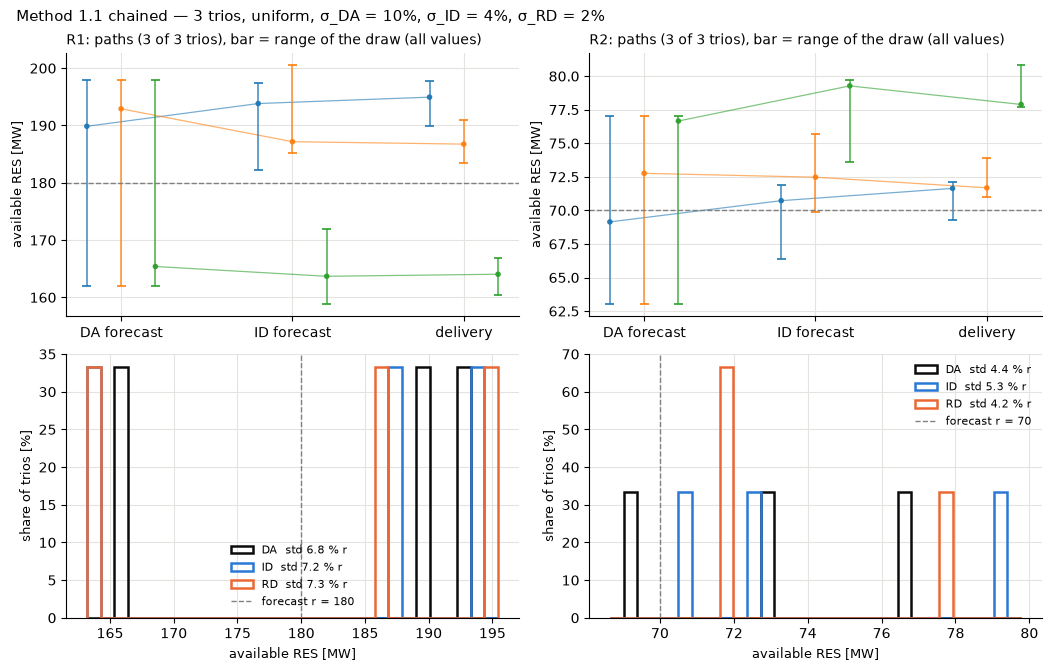

,std DA [% r],std ID [% r],std RD [% r],std RD-DA [% r],std RD-ID [% r],corr DA-ID,corr ID-RD,corr DA-RD
R1,8.38,8.80,8.89,3.13,0.43,0.95,1.00,0.94
R2,5.37,6.45,5.14,2.59,1.70,0.95,0.98,0.88


In [104]:
T11 = trios_chained(r, sigma_da, sigma_id, sigma_rd, N, seed, r_max, units)
plot_trios(T11, r); plt.show()
trio_stats(T11, r)

## Method 1.2: chained, DA fixed

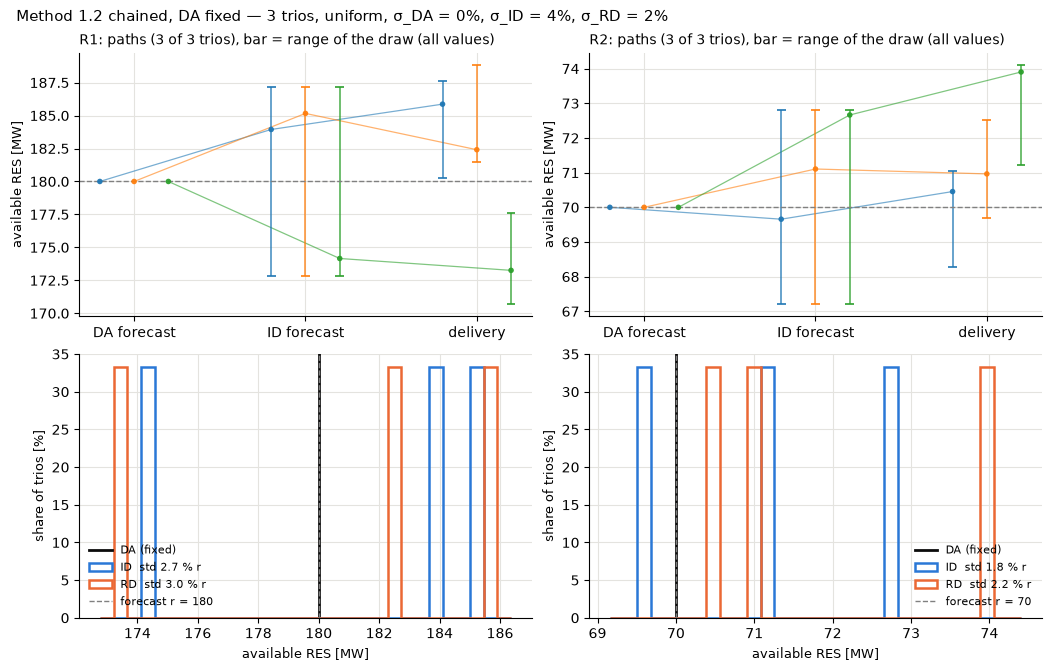

,std DA [% r],std ID [% r],std RD [% r],std RD-DA [% r],std RD-ID [% r],corr DA-ID,corr ID-RD,corr DA-RD
R1,0.0,3.35,3.62,3.62,1.31,NaN,0.93,NaN
R2,0.0,2.15,2.66,2.66,1.01,NaN,0.93,NaN


In [105]:
T12 = trios_chained(r, sigma_da, sigma_id, sigma_rd, N, seed, r_max, units, fix_da=True)
plot_trios(T12, r); plt.show()
trio_stats(T12, r)

## Method 2: centred

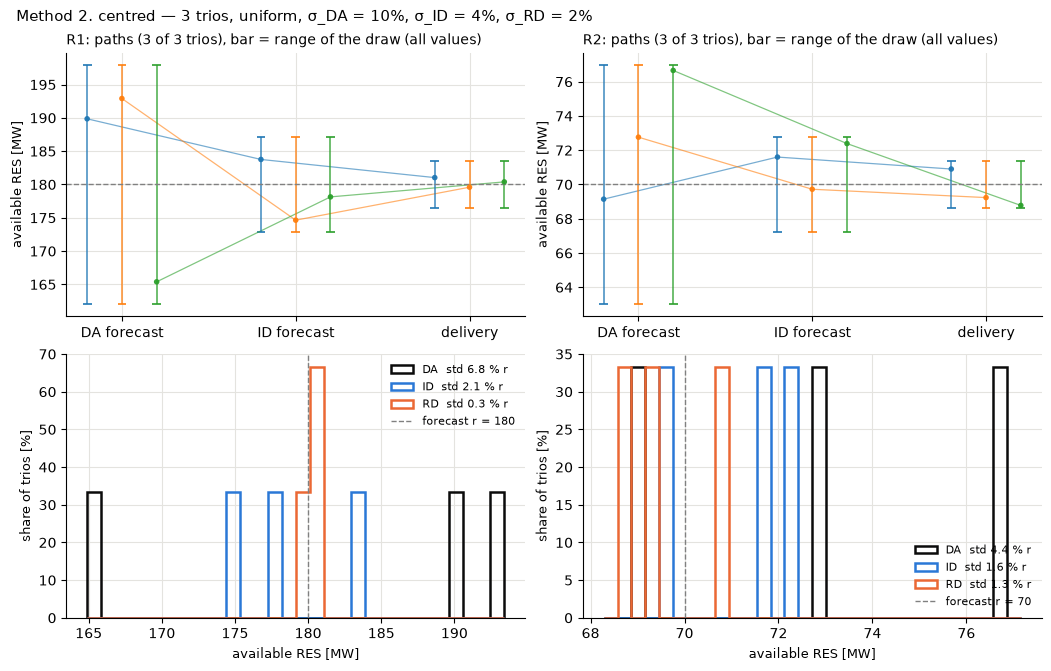

,std DA [% r],std ID [% r],std RD [% r],std RD-DA [% r],std RD-ID [% r],corr DA-ID,corr ID-RD,corr DA-RD
R1,8.38,2.55,0.4,8.46,2.16,0.03,0.98,-0.16
R2,5.37,1.96,1.6,6.90,2.49,0.31,0.03,-0.94


In [106]:
T2 = trios_centred(r, sigma_da, sigma_id, sigma_rd, N, seed, r_max, units)
plot_trios(T2, r); plt.show()
trio_stats(T2, r)

## Method 3: forecast refinement

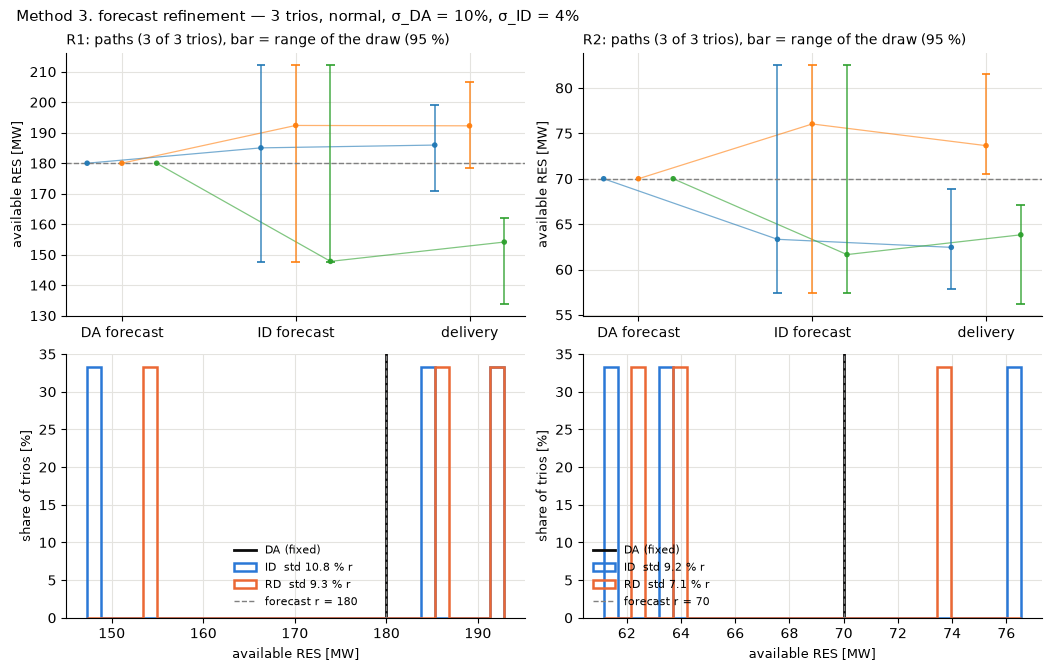

,std DA [% r],std ID [% r],std RD [% r],std RD-DA [% r],std RD-ID [% r],corr DA-ID,corr ID-RD,corr DA-RD
R1,0.0,13.27,11.35,11.35,1.92,NaN,1.00,NaN
R2,0.0,11.24,8.73,8.73,3.32,NaN,0.98,NaN


In [107]:
T3 = trios_forecast(r, sigma_da, sigma_id, N, seed, r_max, units)
plot_trios(T3, r); plt.show()
trio_stats(T3, r)

## Comparison

In [108]:
pd.concat({T["method"]: trio_stats(T, r) for T in (T11, T12, T2, T3)})

std DA [% r]  std ID [% r]  std RD [% r]  \
1.1 chained            R1          8.38          8.80          8.89   
                       R2          5.37          6.45          5.14   
1.2 chained, DA fixed  R1          0.00          3.35          3.62   
                       R2          0.00          2.15          2.66   
2. centred             R1          8.38          2.55          0.40   
                       R2          5.37          1.96          1.60   
3. forecast refinement R1          0.00         13.27         11.35   
                       R2          0.00         11.24          8.73   

                           std RD-DA [% r]  std RD-ID [% r]  corr DA-ID  \
1.1 chained            R1             3.13             0.43        0.95   
                       R2             2.59             1.70        0.95   
1.2 chained, DA fixed  R1             3.62             1.31         NaN   
                       R2             2.66             1.01         NaN   
2. centred             R1             8.46             2.16        0.03   
                       R2             6.90             2.49        0.31   
3. forecast refinement R1            11.35             1.92         NaN   
                       R2             8.73             3.32         NaN   

                           corr ID-RD  corr DA-RD  
1.1 chained            R1        1.00        0.94  
                       R2        0.98        0.88  
1.2 chained, DA fixed  R1        0.93         NaN  
                       R2        0.93         NaN  
2. centred             R1        0.98       -0.16  
                       R2        0.03       -0.94  
3. forecast refinement R1        1.00         NaN  
                       R2        0.98         NaN